# Introduction
In this notebook, we explore the Yelp review dataset to understand its structure, identify frequent aspects, and extract domain-specific sentiment patterns that will guide the ABSA design.

In [1]:
import spacy
import json
import random
import pandas as pd
import seaborn as sns                      
import matplotlib.pyplot as plt
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

In [11]:
sns.set(color_codes=True)
nlp = spacy.load("en_core_web_sm") 

## Dataset Overview & Sampling
The original dataset is retrieved from https://www.kaggle.com/datasets/yelp-dataset/yelp-dataset. The Yelp dataset is extremely large (millions of reviews), so we sample a smaller subset (~20k) for efficient exploration. The original file is in JSON Lines format.

In [ ]:
# Randomly sample ~20k reviews line-by-line (memory-efficient)
input_path = "../data/yelp_academic_dataset_review.json"
output_path = "../data/yelp_sample_20k.json"

sample_size = 20000       
sample_prob = 0.001       

sampled = []
with open(input_path, 'r', encoding='utf-8') as f:
    for line in f:
        if random.random() < sample_prob:
            sampled.append(json.loads(line))
        if len(sampled) >= sample_size:
            break

print(f"Sampled {len(sampled)} reviews")

df = pd.DataFrame(sampled)[["text", "stars"]]
df.to_json(output_path, orient='records', lines=True)
print(f"Saved sample to {output_path}")

This section begins the **Exploratory Data Analysis (EDA)** phase of the ABSA project.  
The goal is to understand the dataset’s structure, content, and sentiment patterns before implementing the main ABSA models.  

We start by loading the dataset, inspecting its structure, and visualizing distributional properties such as:
- Review length
- Star ratings
- Overall sentiment polarity trends  

In [2]:
df = pd.read_json("../data/yelp_sample_20k.json", lines=True)

print(df.info())
print(f"{len(df)} reviews loaded for analysis")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6925 entries, 0 to 6924
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    6925 non-null   object
 1   stars   6925 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 108.3+ KB
None
6925 reviews loaded for analysis


### Data Inspection
We check the dataset’s structure, duplicates, null values, and rating distribution.
This helps ensure data quality before sentiment or aspect analysis.

In [3]:
df.head()

,text,stars
0,Fresh spring water... check!\nHugely portioned...,5
1,"I tried their decaf latte which was tasty, foa...",4
2,Amazing Bagels!! My favorite place ever! Super...,5
3,"Well, I visited UAL for the first time today b...",5
4,Eight of us came here for brunch for my birthd...,4


In [4]:
df.shape

(6925, 2)

In [5]:
df.dtypes

text     object
stars     int64
dtype: object

In [6]:
duplicate_rows_df = df[df.duplicated()]
print("number of duplicate rows: ", duplicate_rows_df.shape)

number of duplicate rows:  (0, 2)


In [7]:
df.count()

text     6925
stars    6925
dtype: int64

In [8]:
print(df.isnull().sum())

text     0
stars    0
dtype: int64


## Review Length and Rating Distribution
We visualize two key aspects of the data:
1. **Review Length Distribution** - helps identify outliers or very short reviews that may not provide meaningful sentiment.
2. **Star Rating Distribution** - reveals whether the dataset is balanced or biased toward positive or negative feedback.

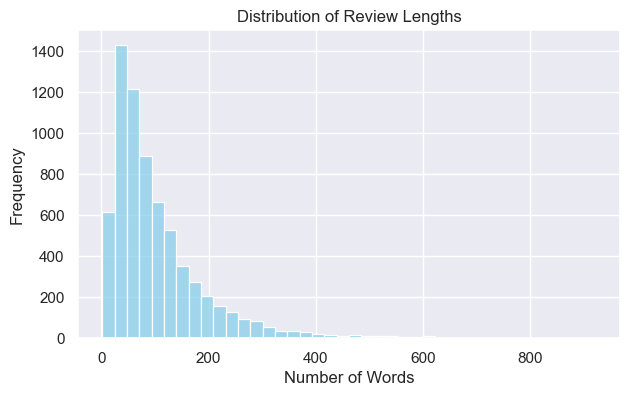

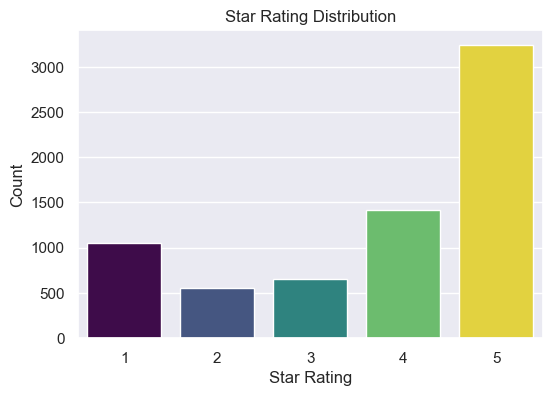

Average review length: 104.6 words


In [12]:
# --- Review Length Distribution ---
df["length"] = df["text"].str.split().apply(len)

plt.figure(figsize=(7,4))
sns.histplot(df["length"], bins=40, color="skyblue")
plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

# --- Star Rating Distribution ---
plt.figure(figsize=(6,4))
sns.countplot(x="stars", data=df, palette="viridis", hue="stars", legend=False)
plt.title("Star Rating Distribution")
plt.xlabel("Star Rating")
plt.ylabel("Count")
plt.show()

print(f"Average review length: {df['length'].mean():.1f} words")


> The dataset is skewed towards 4- and 5-star reviews, which indicates
> a positive sentiment bias. This must be considered when analyzing
> word–rating correlations or training models.

### Text Preprocessing Exploration

We next inspect how **spaCy** tokenizes and parses text data.  
This step allows us to examine:
- Individual tokens  
- Part-of-speech (POS) tags  
- Noun chunks (potential aspect terms)  
- Dependency relations (useful for linking aspects with opinion words)

Understanding the syntactic structure of reviews is crucial for designing **linguistic rules** in the Lexicon-Based ABSA implementation.

In [13]:
df_test = df.copy()
df_test.sample(5, random_state=42)
sample_text = df['text'].iloc[0]
print(sample_text)

doc = nlp(sample_text)

print("Tokens:", [t.text for t in doc])
print("POS Tags:", [(t.text, t.pos_) for t in doc])
print("Noun Chunks:", [chunk.text for chunk in doc.noun_chunks])
print("Dependencies:", [(t.text, t.dep_, t.head.text) for t in doc])


Fresh spring water... check!
Hugely portioned (although on the menu it said regular sized) cobb salad... check!
Cheap prices... check!

During my short stay at Reno, one of my friends checked this place out, came back to the hotel, and urged all of us to come eat here. The food was great. 

If I ever end up back in Reno, I will definitely come back here. I really want to try their "nookie" for breakfast.
Tokens: ['Fresh', 'spring', 'water', '...', 'check', '!', '\n', 'Hugely', 'portioned', '(', 'although', 'on', 'the', 'menu', 'it', 'said', 'regular', 'sized', ')', 'cobb', 'salad', '...', 'check', '!', '\n', 'Cheap', 'prices', '...', 'check', '!', '\n\n', 'During', 'my', 'short', 'stay', 'at', 'Reno', ',', 'one', 'of', 'my', 'friends', 'checked', 'this', 'place', 'out', ',', 'came', 'back', 'to', 'the', 'hotel', ',', 'and', 'urged', 'all', 'of', 'us', 'to', 'come', 'eat', 'here', '.', 'The', 'food', 'was', 'great', '.', '\n\n', 'If', 'I', 'ever', 'end', 'up', 'back', 'in', 'Reno', ',',

### Aspect Frequency Exploration
We identify frequent nouns (potential aspects) from a random 1k sample.
Noun chunks help us see what topics people discuss most often.

In [14]:
docs = list(nlp.pipe(df["text"].sample(1000, random_state=42).tolist()))

In [16]:
# Consider adding food/service-specific terms you DO want
ASPECT_INDICATORS = {
    "FOOD": {"food", "dish", "meal", "entree", "appetizer", "dessert"},
    "SERVICE": {"service", "waiter", "server", "staff", "host"},
    "AMBIANCE": {"atmosphere", "ambiance", "decor", "music"},
    "VALUE": {"price", "value", "portion"}
}

def extract_aspects(doc):
    aspects = []
    
    for np in doc.noun_chunks:
        root = np.root
        
        # Skip pronouns, short words, and determiners
        if root.pos_ in {"PRON", "DET"} or len(root.text) <= 2:
            continue
        
        # Get lemmatized root
        root_lemma = root.lemma_.lower().strip()
        
        # Skip generic terms
        if root_lemma in GENERIC_EXCLUDE:
            continue
        
        # Filter out determiners at the start
        tokens = [t for t in np if t.pos_ not in {"DET", "PRON"}]
        if tokens:
            aspect = " ".join([t.lemma_.lower() for t in tokens])
            aspects.append(aspect)
    
    return aspects

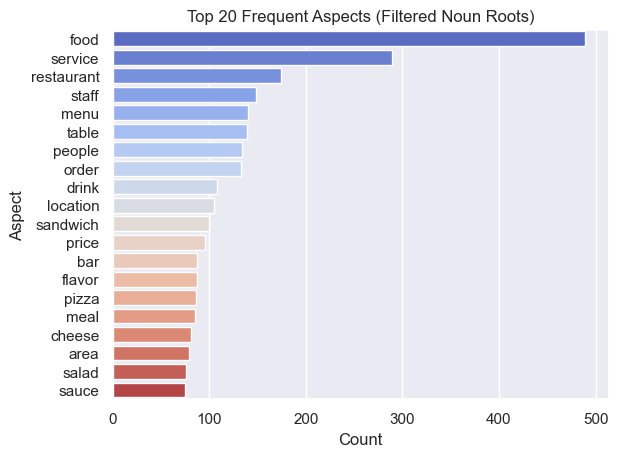

In [17]:
from collections import Counter

# Extract only noun chunks with meaningful noun roots (exclude pronouns and generic words)
GENERIC_EXCLUDE = {
    "thing", "something", "lot", "review", "friend", "day", "weekend", 
    "option", "place", "time", "star", "rating", "reason", "way",
    "everyone", "anyone", "everything", "anything", "bit", "kind",
    "experience", "visit", "hour", "minute", "month", "year"
}
noun_phrases = []
for doc in docs:
    for np in doc.noun_chunks:
        root = np.root
        # filter out pronouns and short tokens
        if root.pos_ not in ["PRON"] and len(root.text) > 2:
            # normalize (lowercase, strip punctuation)
            text = root.lemma_.lower()
            if text not in GENERIC_EXCLUDE:
                noun_phrases.append(text)

aspect_freq = Counter(noun_phrases).most_common(20)
aspect_df = pd.DataFrame(aspect_freq, columns=["aspect", "count"])

# visualize
sns.barplot(x="count", y="aspect", data=aspect_df, palette="coolwarm", hue="aspect", legend=False)
plt.title("Top 20 Frequent Aspects (Filtered Noun Roots)")
plt.xlabel("Count")
plt.ylabel("Aspect")
plt.show()

> **Findings:**  
> After applying linguistic filters, meaningful aspects such as *place*, *food*, *service*, *time*, and *restaurant* emerge clearly.  
> These represent the key dimensions of customer feedback in Yelp reviews — and thus form the **core aspect vocabulary** for later ABSA modeling.

### Discussion: Aspect Frequency Findings
Initially, frequent tokens included pronouns (*I*, *it*, *they*), which are syntactically valid but semantically irrelevant.  
To refine aspect extraction, we applied:
1. **Pronoun filtering** - pronouns like *I*, *they* do not represent concrete aspects.
2. **Generic noun exclusion** - remove non-informative terms like *thing*, *something*, *lot*.
3. **Lemmatization** - unify singular and plural forms (*restaurants → restaurant*). 

This produces a domain-relevant aspect list that improves:
- **Interpretability** of sentiment assignments  
- **Precision** of aspect extraction rules  
- **Downstream ABSA performance** by focusing on review-relevant nouns  


### Sentiment Lexicon Exploration (VADER)
Now we analyze **overall sentiment tendencies** using the **VADER Sentiment Analyzer**.  
VADER provides a compound polarity score ranging from `-1` (negative) to `+1` (positive).  

We will:
- Compute sentiment scores for all reviews.  
- Visualize their distribution.  
- Examine how VADER sentiment correlates with the 1–5 star ratings.


In [18]:
analyzer = SentimentIntensityAnalyzer()

In [19]:
def get_sentiment_score(text):
    return analyzer.polarity_scores(text)['compound']

df_test['sentiment_score'] = df_test['text'].apply(get_sentiment_score)
df_test[['text', 'sentiment_score']].head()

,text,sentiment_score
0,Fresh spring water... check!\nHugely portioned...,0.9283
1,"I tried their decaf latte which was tasty, foa...",0.8469
2,Amazing Bagels!! My favorite place ever! Super...,0.9578
3,"Well, I visited UAL for the first time today b...",0.9795
4,Eight of us came here for brunch for my birthd...,0.9736


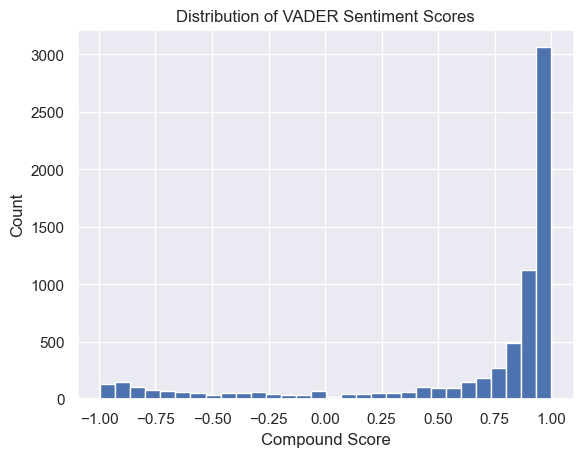

In [20]:
plt.hist(df_test['sentiment_score'], bins=30)
plt.title("Distribution of VADER Sentiment Scores")
plt.xlabel("Compound Score")
plt.ylabel("Count")
plt.show()


We test VADER’s ability to handle negations, a common challenge in sentiment analysis.

In [21]:
samples = ["The food was good", "The food was not good", "The food wasn't bad"]
for s in samples:
    print(s, "→", analyzer.polarity_scores(s)['compound'])


The food was good → 0.4404
The food was not good → -0.3412
The food wasn't bad → 0.431


### Correlation: VADER Sentiment vs. Star Ratings
If the lexicon-based sentiment aligns with user-provided star ratings,
we should observe an upward trend: higher star ratings → higher compound sentiment scores.

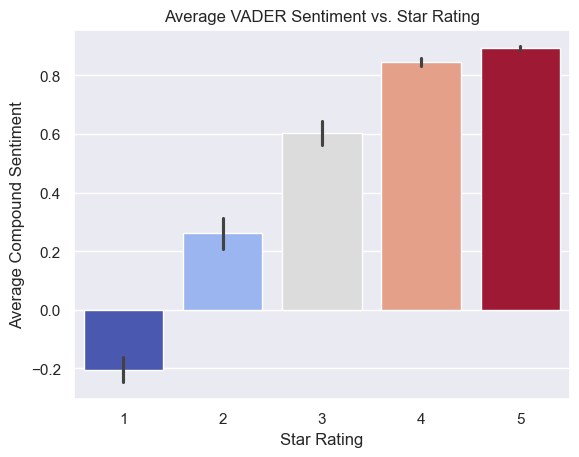

In [22]:
df["compound"] = df["text"].apply(lambda x: analyzer.polarity_scores(x)["compound"])

sns.barplot(x="stars", y="compound", data=df, palette="coolwarm", hue="stars", legend=False)
plt.title("Average VADER Sentiment vs. Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Average Compound Sentiment")
plt.show()

- There is a **strong positive correlation** between VADER sentiment and user star ratings.  
  - **1-star reviews** show negative compound sentiment (≈ –0.2).  
  - **2–3 stars** transition into mild positive sentiment.  
  - **4–5 stars** show clearly positive sentiment, with 5-star reviews approaching +0.9.  
- The **steady upward trend** confirms that the lexicon-based polarity scores align well with the human-annotated star ratings.  
- The **error bars** (confidence intervals) are small, indicating **consistent sentiment behavior** within each rating group.


### Aspect–Sentiment Extraction
Using simple dependency-based rules, we successfully extracted aspect–opinion pairs that capture the key relationships found in Yelp reviews.
Frequent patterns such as **(food, delicious)**, **(service, slow)**, and **(staff, friendly)** match human intuition.

We filtered out pronouns (*I, it, they*) because they do not represent tangible aspects and would otherwise dominate frequency counts.  
By excluding such grammatical subjects, we focus on meaningful entities relevant to ABSA, like *food*, *service*, and *staff*.

This lightweight rule-based prototype mirrors the logic that will later be formalized in the `LexiconABSA` implementation, where each aspect is scored by the sentiment polarity of its associated opinion words.



In [23]:
# Take a smaller sample for faster parsing
sample_texts = df["text"].sample(500, random_state=42).tolist()
docs = list(nlp.pipe(sample_texts))

def extract_aspects(doc):
    aspects = []
    for chunk in doc.noun_chunks:
        # filter out pronouns to avoid non-meaningful aspects
        if chunk.root.pos_ != "PRON":
            aspects.append(chunk.root.lemma_.lower())
    return aspects

def find_opinions(doc, aspects):
    opinions = []
    for token in doc:
        # adjective modifying noun (e.g., "delicious food")
        if token.dep_ == "amod" and token.head.text.lower() in aspects:
            opinions.append((token.head.text.lower(), token.text.lower()))

        # adjective complement (e.g., "food was delicious")
        elif token.dep_ == "acomp":
            # find nominal subject of the same verb
            for child in token.head.children:
                if child.dep_ == "nsubj" and child.lemma_.lower() in aspects:
                    opinions.append((child.text.lower(), token.text.lower()))

        # adverb modifying an adjective or verb (e.g., "bit high")
        elif token.dep_ == "advmod" and token.head.pos_ in ["ADJ", "VERB"]:
            for child in token.head.children:
                if child.dep_ == "nsubj" and child.text.lower() in aspects:
                    opinions.append((child.text.lower(), token.text.lower()))
    return opinions

In [24]:
pairs = []

for text in sample_texts:
    doc = nlp(text)
    aspects = extract_aspects(doc)
    pairs.extend(find_opinions(doc, aspects))

from collections import Counter
pair_freq = Counter(pairs).most_common(15)
pd.DataFrame(pair_freq, columns=["(aspect, opinion)", "count"])


,"(aspect, opinion)",count
0,"(food, good)",31
1,"(staff, friendly)",25
2,"(food, great)",19
3,"(service, great)",17
4,"(service, excellent)",13
5,"(place, great)",12
6,"(food, delicious)",11
7,"(food, amazing)",10
8,"(time, first)",9
9,"(service, good)",9


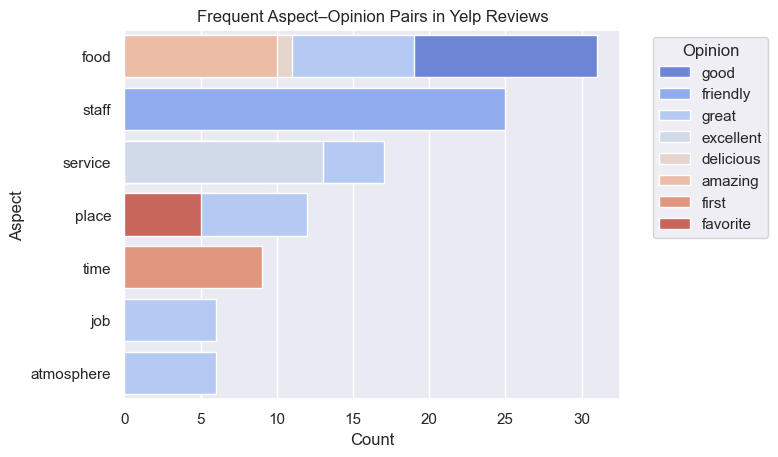

In [25]:
pair_df = pd.DataFrame(pair_freq, columns=["pair", "count"])
pair_df[["aspect", "opinion"]] = pd.DataFrame(pair_df["pair"].tolist(), index=pair_df.index)
pair_df = pair_df.drop(columns="pair")

sns.barplot(x="count", y="aspect", hue="opinion", data=pair_df, dodge=False, palette="coolwarm")
plt.title("Frequent Aspect–Opinion Pairs in Yelp Reviews")
plt.xlabel("Count")
plt.ylabel("Aspect")
plt.legend(title="Opinion", bbox_to_anchor=(1.05, 1))
plt.show()


### Pre-trained ABSA Model Exploration
To understand how transformer-based aspect-based sentiment analysis (ABSA) works, we explore the Hugging Face model `yangheng/deberta-v3-base-absa-v1.1`.
This model expects an input **pair** : a review sentence and a specific aspect and predicts the sentiment toward that aspect.


In [26]:
from transformers import AutoTokenizer,AutoModelForSequenceClassification
import torch

C:\Users\lesle\PycharmProjects\SentimentProject\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [27]:
# To document: needed to install protopuf, sentencepiece
checkpoint = "yangheng/deberta-v3-base-absa-v1.1"
tokenizer = AutoTokenizer.from_pretrained(checkpoint, use_fast=False)
model = AutoModelForSequenceClassification.from_pretrained(checkpoint)

In [32]:
text = "I tried their decaf latte which was tasty, foamy, so good and light that I didn't need to add sugar.The store is cute and the baristas very friendly. The service was slow though"
aspects = ["decaf latte", "service", "store", "baristas"]

# Each pair (sentence + aspect) is tokenized jointly
inputs = tokenizer(
    [(text, aspect) for aspect in aspects],
    padding=True,
    max_length=512, ## Will truncate the sequences that are longer than the model max length
    truncation=True,
    return_tensors="pt"
)
print(inputs)

with torch.no_grad():
    outputs = model(**inputs)
logits = outputs.logits
print("Raw logits:\n", logits)


{'input_ids': tensor([[    1,   273,  1367,   308, 90647, 34533,   319,   284,  7741,   261,
         82172,   261,   324,   397,   263,   731,   272,   273,   590,   280,
           297,   389,   264,   800,  2596,   260,   635,  1106,   269,  3363,
           263,   262, 45150,   268,   379,  2166,   260,   279,   506,   284,
          2364,   651,     2, 90647, 34533,     2],
        [    1,   273,  1367,   308, 90647, 34533,   319,   284,  7741,   261,
         82172,   261,   324,   397,   263,   731,   272,   273,   590,   280,
           297,   389,   264,   800,  2596,   260,   635,  1106,   269,  3363,
           263,   262, 45150,   268,   379,  2166,   260,   279,   506,   284,
          2364,   651,     2,   506,     2,     0],
        [    1,   273,  1367,   308, 90647, 34533,   319,   284,  7741,   261,
         82172,   261,   324,   397,   263,   731,   272,   273,   590,   280,
           297,   389,   264,   800,  2596,   260,   635,  1106,   269,  3363,
           26

> The output logits represent sentiment classes in the order `[negative, neutral, positive]`.  

In [29]:
# Check for the model's max length
print(model.config.max_position_embeddings)

512


In [30]:
# Look-up the model labels
model.config.id2label

{0: 'Negative', 1: 'Neutral', 2: 'Positive'}

- Applying softmax yields normalized probabilities for each class.  
- The highest-probability label is taken as the predicted sentiment toward that aspect.

In [33]:
# Apply softmax to get probabilities
probabilities = torch.nn.functional.softmax(outputs.logits, dim=-1)

#  Convert to label
pred_ids = torch.argmax(probabilities, dim=-1)
labels = [model.config.id2label[i.item()] for i in pred_ids]

# Print Results
for asp, label, score in zip(aspects, labels, probabilities.max(dim=-1).values):
    print(f"Aspect: {asp:<10} → Sentiment: {label:<8} (score={score:.3f})")

Aspect: decaf latte → Sentiment: Positive (score=0.974)
Aspect: service    → Sentiment: Negative (score=0.993)
Aspect: store      → Sentiment: Positive (score=0.994)
Aspect: baristas   → Sentiment: Positive (score=0.993)


> As expected, the model correctly identifies *decaf latte → positive*
  *service → negative*, *store → positive* and *barista → positive* .
> This validates that the transformer pipeline is functioning as intended and can serve as the foundation for our `TransformerABSA` implementation.


The Model `yangheng/deberta-v3-base-absa-v1.1` does not do aspect extraction directly so we explored another model `yangheng/deberta-v3-base-end2end-absa`. This model jointly extracts aspect terms and their sentiments via a single token-classification head.

In [4]:
from transformers import pipeline

nlp = pipeline(
    "token-classification",
    model="yangheng/deberta-v3-base-end2end-absa",
    use_fast=True,
    aggregation_strategy="simple"
)

text = "I tried their decaf latte which was tasty, foamy, so good and light that I didn't need to add sugar.The store is cute and the baristas very friendly. It has a private parking lot but it's always packed.I definitely come back on my next visit to Santa Barbara."

preds = nlp(text)

# Pretty print the results
print("ASPECT-BASED SENTIMENT ANALYSIS RESULTS")

for i, pred in enumerate(preds, 1):
    print(f"Result {i}:")
    print(f"  Entity: {pred['word']}")
    print(f"  Label: {pred['entity_group']}")
    print(f"  Score: {pred['score']:.4f}")
    print(f"  Position: characters {pred['start']}-{pred['end']}")
    print()

Device set to use cpu
Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.



ASPECT-BASED SENTIMENT ANALYSIS RESULTS

Result 1:
  Entity: decaf latte
  Label: ASP-Neutral
  Score: 0.7115
  Position: characters 13-25

Result 2:
  Entity: sugar
  Label: ASP-Neutral
  Score: 0.6003
  Position: characters 93-99

Result 3:
  Entity: store
  Label: ASP-Neutral
  Score: 0.6957
  Position: characters 103-109

Result 4:
  Entity: baristas
  Label: ASP-Neutral
  Score: 0.6780
  Position: characters 125-134

Result 5:
  Entity: parking lot
  Label: ASP-Neutral
  Score: 0.6952
  Position: characters 166-178



> Though the model excell at extracting aspects, its sentiment analysis is not quite performant. Hence, we will consider using both models to implement the TransfromerABSA